# For plotting

In [1]:
from math import sqrt,pi
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad,simpson
import matplotlib
matplotlib.rcParams['axes.prop_cycle'] = matplotlib.cycler(color=[
    (63/255,144/255,218/255),(255/255,169/255,14/255),(189/255,31/255,1/255),(148/255,164/255,162/255),(131/255,45/255,182/255),(169/255,107/255,89/255),(231/255,99/255,0),(185/255,172/255,112/255),(113/255,117/255,129/255),(146/255,218/255,221/255)]) 
colortablet = plt.rcParams['axes.prop_cycle'].by_key()['color']

Config options

In [2]:
output_folder = '../output/save/0812.0919/'
outputnoGammat_folder = '../output/save/0812.0919-Gammat-0/'
myoutput_folder = '../output/save/my-singlet-LO/'
myNLOoutput_folder = '../output/save/my-singlet-NLO/'

### Green function

Read data files

In [3]:
file_path = output_folder + 'greenfunction.dat'
mtt,imG_singlet,imG_octet = np.loadtxt(file_path, comments='#', usecols=(0,1,2), unpack=True)
file_path = outputnoGammat_folder + 'greenfunction.dat'
mtt_nodecay,imG_singlet_nodecay,imG_octet_nodecay = np.loadtxt(file_path, comments='#', usecols=(0,1,2), unpack=True)
file_path = myoutput_folder + 'greenfunction.dat'
mtt_my,imG_mysinglet = np.loadtxt(file_path, comments='#', usecols=(0,1), unpack=True)

Plots

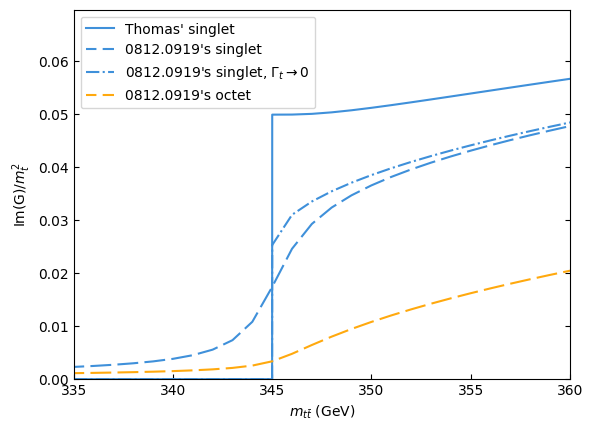

In [4]:
plt.figure()
plt.plot(mtt_my,imG_mysinglet/172.5**2, label='Thomas\' singlet', color=colortablet[0])
plt.plot(mtt,imG_singlet/172.5**2, label='0812.0919\'s singlet', color=colortablet[0], linestyle=(5, (10, 3)))
plt.plot(mtt_nodecay,imG_singlet_nodecay/172.5**2, label='0812.0919\'s singlet, $\\Gamma_t \\to 0$', color=colortablet[0], linestyle='-.')
plt.plot(mtt,imG_octet/172.5**2, label='0812.0919\'s octet', color=colortablet[1], linestyle=(5, (10, 3)))
plt.xlabel('$m_{t\\bar{t}}$ (GeV)')
plt.ylabel('Im(G)/$m_t^2$')
plt.ylim(0)
plt.legend()
plt.tick_params(axis='both', which='major',direction='in', right=True)
plt.xlim(335,360)
plt.savefig('greenfunction.pdf', bbox_inches='tight')
plt.show()

### Differential cross section

Read data files

In [5]:
file_path = output_folder + 'dist_mtt.dat'
mtt,dxsect_gg_1S01,dxsect_gg_1S08,dxsect_qq_3S18 = np.loadtxt(file_path, comments='#', usecols=(0,1,4,7), unpack=True)
file_path = myoutput_folder + 'dist_mtt.dat'
mtt_my,dxsect_gg_1S01_my = np.loadtxt(file_path, comments='#', usecols=(0,1), unpack=True)
file_path = myNLOoutput_folder + 'dist_mtt.dat'
mtt_myrawNLO,dxsect_gg_1S01_myrawNLO = np.loadtxt(file_path, comments='#', usecols=(0,1), unpack=True)
ind_nonzero = np.where(dxsect_gg_1S01_myrawNLO != 0)[0][0]
mtt_myrawNLO = mtt_myrawNLO[ind_nonzero:]
dxsect_gg_1S01_myrawNLO = dxsect_gg_1S01_myrawNLO[ind_nonzero:]

Plots

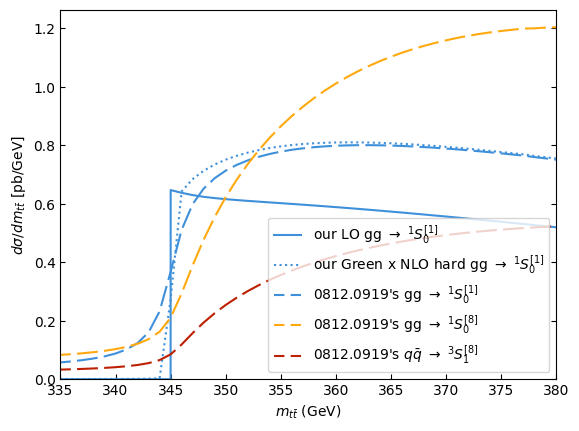

In [6]:
plt.figure()
plt.plot(mtt_my,dxsect_gg_1S01_my, label='our LO gg $\\to$ $^1S_0^{[1]}$', color=colortablet[0])
plt.plot(mtt_myrawNLO,dxsect_gg_1S01_myrawNLO, label='our Green x NLO hard gg $\\to$ $^1S_0^{[1]}$', color=colortablet[0], linestyle=':')
plt.plot(mtt,dxsect_gg_1S01, label='0812.0919\'s gg $\\to$ $^1S_0^{[1]}$', color=colortablet[0], linestyle=(5, (10, 3)))
plt.plot(mtt,dxsect_gg_1S08, label='0812.0919\'s gg $\\to$ $^1S_0^{[8]}$', color=colortablet[1], linestyle=(5, (10, 3)))
plt.plot(mtt,dxsect_qq_3S18, label='0812.0919\'s $q\\bar{q}$ $\\to$ $^3S_1^{[8]}$', color=colortablet[2], linestyle=(5, (10, 3)))
# plt.plot(mtt,dxsect_gg_1S08+dxsect_qq_3S18, label='0812.0919\'s total octet', color=colortablet[3], linestyle=(5, (10, 3)))
plt.xlabel('$m_{t\\bar{t}}$ (GeV)')
plt.ylabel('$d\\sigma/dm_{t\\bar{t}}$ [pb/GeV]')
plt.ylim(0)
plt.legend()
plt.xlim(np.min(mtt),np.max(mtt))
plt.tick_params(axis='both', which='major',direction='in', right=True)
plt.savefig('dist_mtt.pdf', bbox_inches='tight')
plt.show()

## Running of $\alpha_s$

In [2]:
import rundec # See https://github.com/DavidMStraub/rundec-python

crd = rundec.CRunDec()
alphas_MZ=0.1181 # See 1703.03751
MZ = 91.1876    # GeV
mt = 172.56     # GeV
Gammat = 1.36   # GeV
nfMmu_t=rundec.TriplenfMmu()
nfMmu_t.nf=6
nfMmu_t.Mth=mt
nfMmu_t.muth=mt
nfMmu_b=rundec.TriplenfMmu()
nfMmu_b.nf=5
nfMmu_b.Mth=4.163
nfMmu_b.muth=4.163
nfMmu_c=rundec.TriplenfMmu()
nfMmu_c.nf=4
nfMmu_c.Mth=1.279
nfMmu_c.muth=3
def run_alpha_s(mu):
    if mu < nfMmu_t.muth and mu >= nfMmu_b.muth: # between b and t -> 5 flavours
        return crd.AlphasExact(alphas_MZ,MZ,mu,5,5)
    elif mu >= nfMmu_t.muth:
        # raise NotImplementedError("Not implemented. See crd.crd.AlL2AlH")
        return crd.AlphasExact(alphas_MZ,MZ,mu,5,5)
    elif mu < nfMmu_b.muth and mu >= nfMmu_c.muth: # between c and b -> 4 flavours
        nfMmu_array = rundec.TriplenfMmuArray(5)
        nfMmu_array[0] = nfMmu_b
        return crd.AlH2AlL(ash=alphas_MZ,mu1=MZ,decpar=nfMmu_array,mu2=mu,nloops=4)
    elif mu < nfMmu_c.muth and mu >= 0.506: # between mc and 0.6 GeV
        nfMmu_array = rundec.TriplenfMmuArray(5)
        nfMmu_array[0] = nfMmu_b
        nfMmu_array[1] = nfMmu_c
        return crd.AlH2AlL(ash=alphas_MZ,mu1=MZ,decpar=nfMmu_array,mu2=mu,nloops=3)
    else:
        raise ValueError("mu too small. Running breaks down.")
print("alpha_s( mtau = 1.7769 ) =",f"{run_alpha_s(1.7769):.4g}. Expected 0.314")

alpha_s( mtau = 1.7769 ) = 0.3125. Expected 0.314


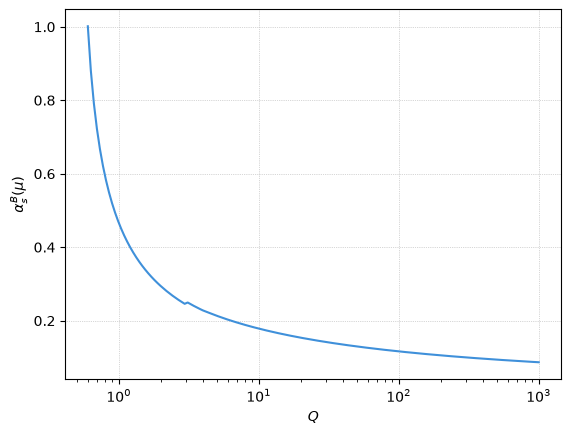

In [3]:
import numpy as np
import matplotlib.pyplot as plt

x = np.logspace(np.log10(0.6),3,150)
y = np.asarray([run_alpha_s(mu) for mu in x])

plt.figure()
plt.plot(x, y, label='$\\alpha^B_s(\\mu)$')
plt.xlabel('$Q$')
# plt.yscale('log')
plt.ylabel('$\\alpha^B_s(\\mu)$')
plt.xscale('log')
# plt.xlim(1, 1000)
# plt.title('Plot of f(x)')
plt.grid(True, linestyle=':', linewidth=0.5)
# plt.legend()
plt.savefig('running-alphaS.pdf', bbox_inches='tight')
plt.show()

alpha_s^B = alpha_s(Q = mt/2 * 4*alpha_s^B/3) =  0.1568
alpha_s^B_SF(v_rel=0) =  0.3026
Q(v_rel=0) =  1.887 GeV


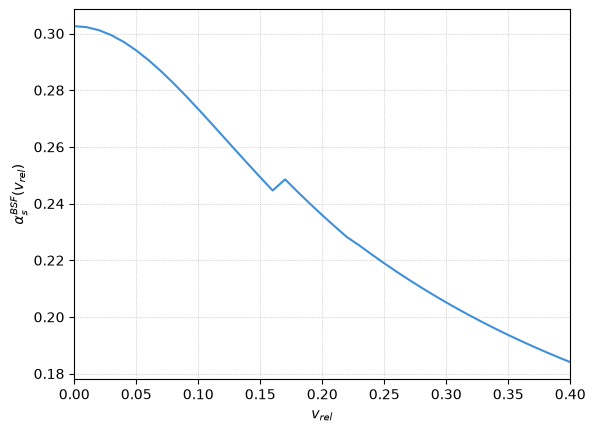

In [4]:
# Compute alphas_B. To get alphag_B, multiply by 4/3
def find_alphas_B(alpha_s_guess=0.15,mt=mt,tol=1e-6):
    new_alpha_s = alpha_s_guess
    old_alpha_s = 0
    while abs(new_alpha_s - old_alpha_s) > tol:
        old_alpha_s = new_alpha_s
        mu_B = (4/3) * old_alpha_s * mt/2
        new_alpha_s = run_alpha_s(mu_B)
    return new_alpha_s

alphas_B = find_alphas_B()
print("alpha_s^B = alpha_s(Q = mt/2 * 4*alpha_s^B/3) = ", f"{alphas_B:.4g}")
v_rel_arr = np.linspace(0,0.4,41)
Q_BSF_arr = mt/4 * (v_rel_arr**2 + (4*alphas_B/3)**2)
alphas_BSF_arr = np.asarray([run_alpha_s(Q) for Q in Q_BSF_arr])
print("alpha_s^B_SF(v_rel=0) = ", f"{alphas_BSF_arr[0]:.4g}")
print("Q(v_rel=0) = ", f"{Q_BSF_arr[0]:.4g} GeV")

plt.figure()
plt.plot(v_rel_arr, alphas_BSF_arr, label='$\\alpha_s^{BSF}(v_{rel})$')
plt.xlabel('$v_{rel}$')
plt.ylabel('$\\alpha_s^{BSF}(v_{rel})$')
plt.xlim(v_rel_arr[0], v_rel_arr[-1])
plt.grid(True, linestyle=':', linewidth=0.5)
plt.savefig('alphas_vs_vrel.pdf', bbox_inches='tight')
plt.show()

#### Integrand of overlap integral

In [5]:
# Bound state constants
alphag_B = 4/3*alphas_B
kappa = mt*alphag_B/2

In [71]:
kappa**2/mt

1.886631049201586

In [6]:
def S0_Sommerfeld(x):
    return 2*np.pi*x / (1 - np.exp(-2*np.pi*x))

In [ ]:
def ISI_integrand(k,s_parton):
    ''' k in GeV, s_parton in GeV^2 '''
    alphas_NA = run_alpha_s(np.sqrt(kappa**2 + k**2))
    alphag_S = -run_alpha_s(k)/6
    zetaS = mt*alphag_S/(2*k)
    zetaB = mt*alphag_B/(2*k)
    Energy_k = k**2/mt
    
    return (4*np.pi)/(2*np.pi)**3 * (-8j*np.sqrt(np.pi)*(1j+zetaS)**2*S0_Sommerfeld(zetaS)) / (np.sqrt(s_parton)-2*mt-Energy_k+1j*Gammat) * (3*alphag_B/alphas_NA + 2) * np.exp(-2*zetaS*np.arctan(1/zetaB)) / (1+zetaB**2)**2

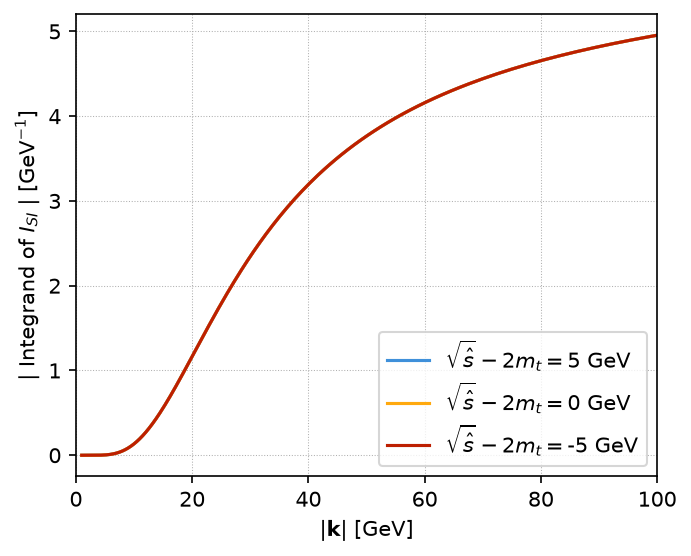

In [70]:
k_arr = np.logspace(np.log10(1),np.log10(100),401)

plt.figure(figsize=(5,4),dpi=150)
for dS in [5,0,-5]:
    sqrt_s = 2*mt+dS
    ISI_integrand_arr = np.abs(np.asarray([ISI_integrand(k,sqrt_s**2) for k in k_arr]))
    plt.plot(k_arr, ISI_integrand_arr, label='$\\sqrt{\\hat{s}}-2m_t = $'+f'{dS} GeV')
plt.xlabel('$|\\mathbf{k}|$ [GeV]')
# plt.yscale('log')
plt.ylabel('| Integrand of $I_{SI}$ | [GeV$^{-1}$]')
# plt.xscale('log')
plt.xlim(0, 100)
# plt.title('Plot of f(x)')
plt.grid(True, linestyle=':', linewidth=0.5)
plt.legend()
plt.savefig('ISI_integrand.pdf', bbox_inches='tight')
plt.show()

In [9]:
def ISI(s_parton,k_min=1,k_max=1000):
    ''' Integrate ISI '''
    return quad(ISI_integrand,a=k_min,b=k_max,args=(s_parton),complex_func=True)

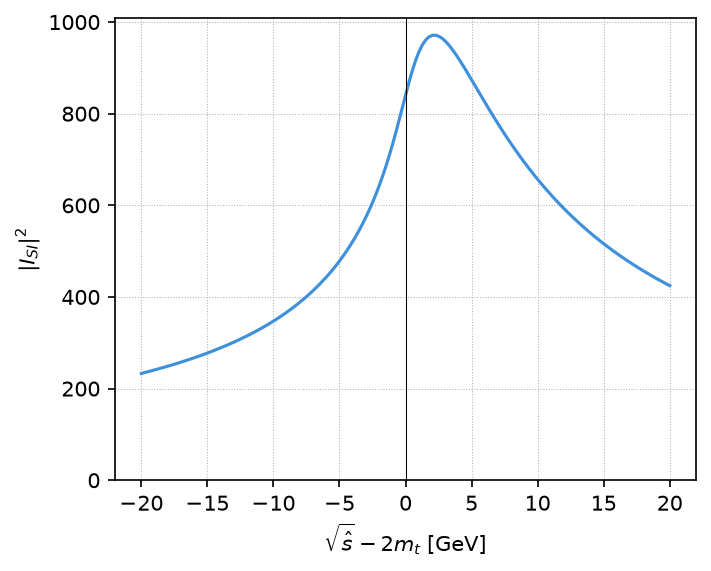

In [10]:
sqrt_s_arr = np.linspace(2*mt-20,2*mt+20,161)
ISI_arr = np.abs(np.asarray([ISI(sqrt_s**2)[0] for sqrt_s in sqrt_s_arr]))

plt.figure(figsize=(5,4),dpi=150)
plt.plot(sqrt_s_arr-2*mt, ISI_arr**2, label='$I_{SI}$')
plt.axvline(x=0,color='k',linewidth=0.5)
plt.xlabel('$\\sqrt{\\hat{s}} - 2m_t$ [GeV]')
plt.ylim(0)
plt.ylabel('$|I_{SI}|^2$')
plt.grid(True, linestyle=':', linewidth=0.5)
plt.savefig('ISI.pdf', bbox_inches='tight')
plt.show()

In [11]:
print("An integral over alphaS is perfectly convergent")
print(quad(run_alpha_s,a=1,b=20))
print(quad(run_alpha_s,a=0.506,b=20))

An integral over alphaS is perfectly convergent
(3.6846700595283712, 2.1402358552080614e-08)
(4.095783489286399, 4.857719382300729e-08)


#### Diff xsection

In [74]:
partonic_luminosity = 63636.8
alphas_at_2mt = run_alpha_s(2*mt)
s_hadron = 13600**2 # GeV^2
binding_energy_toponium = -mt*alphag_B**2/4
invGeV2topb = 0.389379e9
Mtt_integrate_max = 2*mt + 50   # GeV
LambdaQCD = 0.53    # GeV

In [13]:
def integrand_integrate_over_s_parton(tau,rho):
    # Eg = s_hadron/(4*mt) * (tau-rho)
    Eg = s_hadron/(4*mt) * (tau-rho)
    s_parton = tau*s_hadron
    return (tau-rho) * run_alpha_s(Eg) * np.abs(ISI(s_parton)[0])**2

In [14]:
[quad(integrand_integrate_over_s_parton,a=(Mtt+LambdaQCD)**2/s_hadron,b=Mtt_integrate_max**2/s_hadron,args=(Mtt**2/s_hadron))[0] for Mtt in [2*mt-10, 2*mt, 2*mt+2, 2*mt+10]]

[1.4354277741312395e-06,
 9.495374633615052e-07,
 8.589827212820852e-07,
 5.628455493567942e-07]

Total gluon emission cross section:  3252.7232390384934 pb


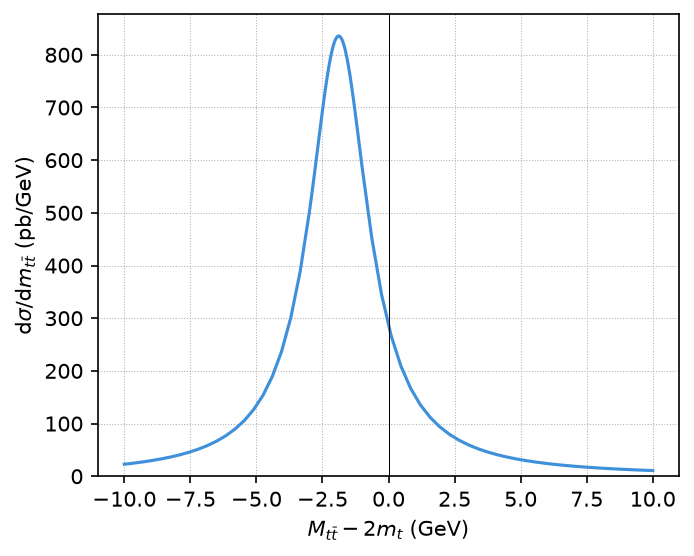

In [76]:
plt.figure(figsize=(5,4),dpi=150)

Mtt_arr = np.concatenate([np.linspace(2*mt-10,2*mt-3,20,endpoint=False),np.linspace(2*mt-3,2*mt-1,40,endpoint=False),np.linspace(2*mt-1,2*mt+10,31)])
BreitWigner_arr = Gammat / ((Mtt_arr - 2*mt - binding_energy_toponium)**2 + Gammat**2)
# tau_integral_arr = np.array([quad(integrand_integrate_over_s_parton,a=(Mtt+LambdaQCD)**2/s_hadron,b=Mtt_integrate_max**2/s_hadron,args=(Mtt**2/s_hadron))[0] for Mtt in Mtt_arr])
dxsect_dMtt = alphas_at_2mt**2 * alphag_B**5 * np.pi*s_hadron/(2**11*3**3*mt**4) * BreitWigner_arr * partonic_luminosity * invGeV2topb #* tau_integral_arr
print("Total gluon emission cross section: ",simpson(dxsect_dMtt,Mtt_arr),"pb")
plt.plot(Mtt_arr-2*mt, dxsect_dMtt)
plt.axvline(x=0,color='k',linewidth=0.5)
plt.xlabel('$M_{t \\bar{t}} - 2m_t$ (GeV)')
plt.ylabel('d$\\sigma$/d$m_{t\\bar{t}}$ (pb/GeV)')
plt.ylim(0)
plt.grid(True, linestyle=':', linewidth=0.5)
plt.savefig('dxsect_gluon_emission.pdf', bbox_inches='tight')
plt.show()